In [1]:
import os

try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN").strip()
except ImportError:
    if "KAGGLE_API_TOKEN" not in os.environ:
        from getpass import getpass
        os.environ["KAGGLE_API_TOKEN"] = getpass("KAGGLE_API_TOKEN: ").strip()


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [4]:
import kagglehub

path = kagglehub.competition_download('multiple-object-video-detection-hw-2-ucu-ai-2026')

print("Path to competition files:", path)

Path to competition files: /Users/ruzhylopv/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


# Data Understanding

## Overview

The task is VisDrone2019-VID style detection: 8 classes, drone footage, small and densely packed objects. Before choosing any model I want to answer five questions that directly drive the experiments below:

1. **Class balance**: how skewed is it, and does `val` look like `train`?
2. **Object size**: how small are the objects, and what input resolution do they need?
3. **Resolution**: are `train`, `val` and `test` images at comparable scale?
4. **Density and ignore regions**: how crowded are the frames, and how much of each frame is "don't care"?
5. **Label quality**: how occluded and truncated are the objects?

In [ ]:
import json
from pathlib import Path

from PIL import Image

DATA = Path(path)
CLASS_NAMES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})


def load_coco(split):
    """COCO json -> (frames, objects, ignore regions). Class ids are made 0-based like YOLO / the submission."""
    d = json.load(open(DATA / split / "annotations_coco.json"))
    frames = pd.DataFrame(d["images"]).rename(columns={"id": "image_id", "video": "clip"})
    ann = pd.DataFrame(d["annotations"])
    ann[["x", "y", "w", "h"]] = pd.DataFrame(ann["bbox"].tolist(), index=ann.index)
    ann = ann.merge(frames[["image_id", "clip", "frame_id", "width", "height"]], on="image_id")

    # COCO stores every ignore region once per class (so evaluation applies it to all categories): keep one copy
    regions = ann[ann.iscrowd == 1].drop_duplicates(["image_id", "x", "y", "w", "h"]).reset_index(drop=True)
    objs = ann[ann.iscrowd == 0].copy()
    objs["cls"] = objs.category_id - 1
    objs["cls_name"] = objs.cls.map(dict(enumerate(CLASS_NAMES)))
    objs["long_side"] = objs[["width", "height"]].max(axis=1)
    objs["size_px"] = np.sqrt(objs.w * objs.h)            # sqrt(area) in native pixels
    objs["size_rel"] = objs.size_px / objs.long_side      # resolution-independent size
    return frames, objs.reset_index(drop=True), regions


train_frames, train_objs, train_regions = load_coco("train")
val_frames, val_objs, val_regions = load_coco("val")
test_frames = pd.read_csv(DATA / "test_images.csv")

summary = pd.DataFrame({
    "train": [train_frames["clip"].nunique(), len(train_frames), len(train_objs), len(train_regions), train_regions.image_id.nunique()],
    "val": [val_frames["clip"].nunique(), len(val_frames), len(val_objs), len(val_regions), val_regions.image_id.nunique()],
    "test": [test_frames["clip"].nunique(), len(test_frames), np.nan, np.nan, np.nan],
}, index=["clips", "frames", "objects", "ignore regions", "frames with ignore regions"])
summary.map(lambda v: "-" if pd.isna(v) else f"{int(v):,}")

,train,val,test
clips,56,7,48
frames,"24,201","2,846","3,811"
objects,"1,105,516","114,132",-
ignore regions,"63,843","3,995",-
frames with ignore regions,"18,090","1,434",-


## 1. Class balance

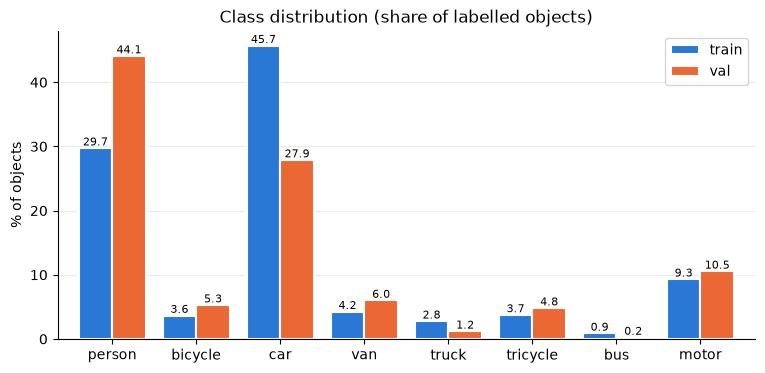

car : bus ratio in train = 52 : 1


,train,val,train_pct,val_pct
cls_name,,,,
person,328701,50312,29.7,44.1
bicycle,40255,6022,3.6,5.3
car,505301,31821,45.7,27.9
van,46940,6842,4.2,6.0
truck,30498,1359,2.8,1.2
tricycle,41349,5487,3.7,4.8
bus,9653,264,0.9,0.2
motor,102819,12025,9.3,10.5


In [ ]:
counts = pd.DataFrame({
    "train": train_objs.cls_name.value_counts(),
    "val": val_objs.cls_name.value_counts(),
}).reindex(CLASS_NAMES)
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 4))
share.plot.bar(ax=ax, color=[BLUE, ORANGE], width=0.8, rot=0, edgecolor="white", linewidth=1.5)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8)
ax.set_ylabel("% of objects")
ax.set_xlabel("")
ax.set_title("Class distribution (share of labelled objects)")
ax.grid(axis="x", visible=False)
plt.show()

print(f"car : bus ratio in train = {counts.train['car'] / counts.train['bus']:.0f} : 1")
counts.assign(train_pct=share.train.round(1), val_pct=share.val.round(1)).astype({"train": int, "val": int})

**Observations**

- The distribution is heavily long-tailed: `car` (46%) and `person` (30%) make up three quarters of the train objects, while `bus` is under 1% (about 50 times rarer than `car`) and `truck`, `tricycle`, `bicycle` and `van` are each only 3-4%.
- `val` is **not** distributed like `train`: `person` is the largest class there (44%) and `car` drops to 28%. Only 7 clips are in `val`, so class mix is dominated by a few scenes.
- `val` has only 264 `bus` and 1,359 `truck` instances, so per-class AP on those classes will be very noisy. I will look at mAP overall and treat per-class `bus`/`truck` numbers with caution.

**Implication:** the rare classes (`bus`, `truck`, `van`, `tricycle`, `bicycle`) need attention: class-aware loss weighting or focal-style losses, and augmentation that does not remove them (e.g. no aggressive random crops that drop large objects).

## 2. Object size

Pixel sizes are not comparable across clips because image resolutions differ (see section 3), so I express size as `sqrt(w*h) / long_side` (resolution independent) and report it in pixels at a fixed reference input of 1280 px on the long side.

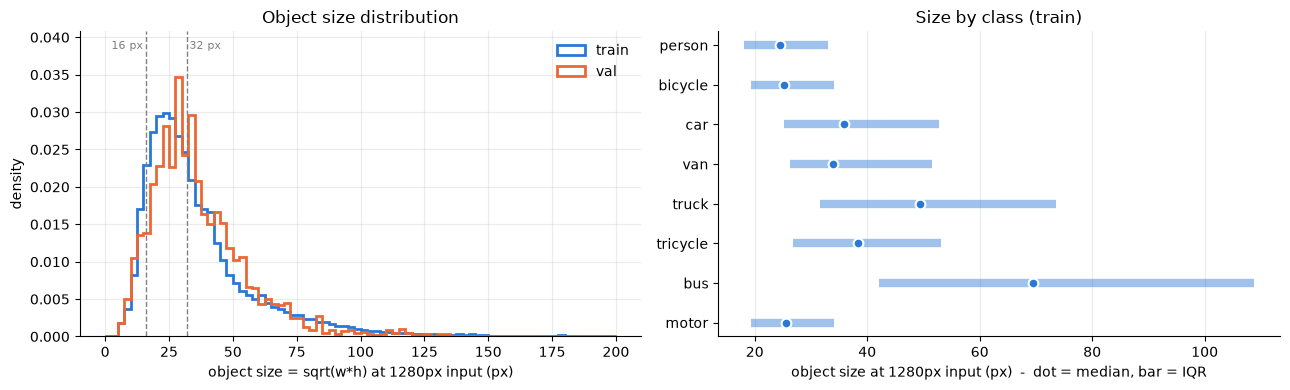

,< 8 px,< 16 px,< 32 px,< 64 px
train,0.6%,9.8%,54.2%,89.0%
val,0.7%,8.7%,48.4%,91.1%


In [ ]:
REF = 1280  # reference long side (px) used to compare object sizes across resolutions
for o in (train_objs, val_objs):
    o["size_ref"] = o.size_rel * REF

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

bins = np.linspace(0, 200, 81)
ax[0].hist(train_objs.size_ref, bins=bins, density=True, histtype="step", lw=2, color=BLUE, label="train")
ax[0].hist(val_objs.size_ref, bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label="val")
ax[0].set_ylim(top=ax[0].get_ylim()[1] * 1.12)
for t, ha, dx in [(16, "right", -1), (32, "left", 1)]:
    ax[0].axvline(t, color="grey", ls="--", lw=1)
    ax[0].text(t + dx, ax[0].get_ylim()[1] * 0.97, f"{t} px", fontsize=8, color="grey", ha=ha, va="top")
ax[0].set_xlabel(f"object size = sqrt(w*h) at {REF}px input (px)")
ax[0].set_ylabel("density")
ax[0].set_title("Object size distribution")
ax[0].legend(frameon=False)

q = train_objs.groupby("cls_name").size_ref.quantile([0.25, 0.5, 0.75]).unstack().reindex(CLASS_NAMES)
y = np.arange(len(CLASS_NAMES))
ax[1].hlines(y, q[0.25], q[0.75], color=BLUE, lw=6, alpha=0.45)
ax[1].plot(q[0.5], y, "o", color=BLUE, ms=7, mec="white", mew=1.5)
ax[1].set_yticks(y, CLASS_NAMES)
ax[1].invert_yaxis()
ax[1].grid(axis="y", visible=False)
ax[1].set_xlabel(f"object size at {REF}px input (px)  -  dot = median, bar = IQR")
ax[1].set_title("Size by class (train)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    name: {f"< {t} px": (o.size_ref < t).mean() for t in (8, 16, 32, 64)}
    for name, o in [("train", train_objs), ("val", val_objs)]
}).T.map("{:.1%}".format)

**Observations**

- Objects are small: the median object is only about 2.4% of the image's long side, i.e. ~30 px at a 1280 px input. About half of all boxes are under 32 px (54% in train, 48% in val; the COCO "small" range) and roughly 1 in 10 is under 16 px.
- `person`, `motor` and `bicycle` are the smallest classes; `bus` and `truck` are 3-4x larger. Large and tiny objects therefore co-exist in the same frames, so a multi-scale detector (FPN / PAN neck, small-object heads) is needed.
- Train and val size distributions agree well, so val is a fair proxy for size-related behaviour.

**Implication:** the input resolution is a first-order choice. Default 640 px inputs would shrink about half of all objects below 16 px. I quantify this in the preprocessing section and pick a larger training/inference size.

## 3. Image resolution: train vs val vs test

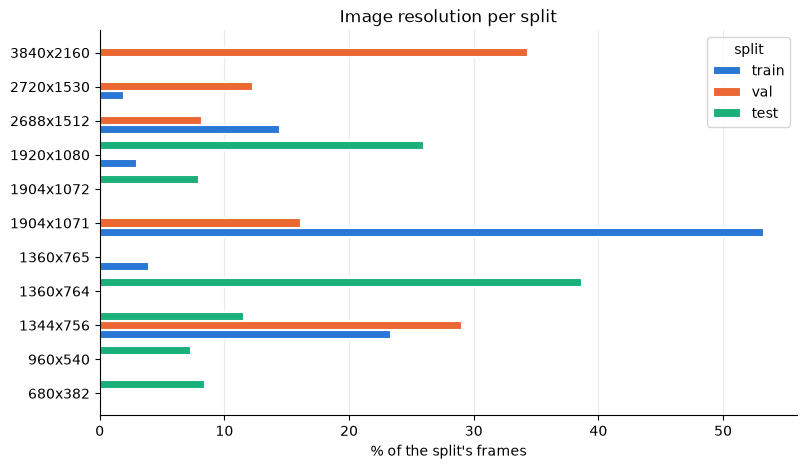

median long side: train 1904 px | test 1360 px (max 2720 vs 1920)
median object size at native resolution: train 46 px | test (assuming the same relative size) ~32 px


In [ ]:
def clip_table(frames):
    return frames.groupby("clip").agg(width=("width", "first"), height=("height", "first"), frames=("width", "size"))

res = pd.concat({"train": clip_table(train_frames), "val": clip_table(val_frames), "test": clip_table(test_frames)},
                names=["split", "clip"]).reset_index()
res["resolution"] = res.width.astype(str) + "x" + res.height.astype(str)

frames_by_res = res.pivot_table(index=["width", "height"], columns="split", values="frames", aggfunc="sum", fill_value=0)
frames_pct = (frames_by_res / frames_by_res.sum() * 100)[["train", "val", "test"]]
frames_pct.index = [f"{w}x{h}" for w, h in frames_pct.index]

ax = frames_pct.plot.barh(figsize=(9, 5), color=[BLUE, ORANGE, AQUA], width=0.8, edgecolor="white", linewidth=1.5)
ax.set_xlabel("% of the split's frames")
ax.set_ylabel("")
ax.set_title("Image resolution per split")
ax.grid(axis="y", visible=False)
plt.show()

test_long = test_frames[["width", "height"]].max(axis=1)
train_long = train_frames[["width", "height"]].max(axis=1)
print(f"median long side: train {train_long.median():.0f} px | test {test_long.median():.0f} px (max {train_long.max()} vs {test_long.max()})")
print(f"median object size at native resolution: train {train_objs.size_px.median():.0f} px | "
      f"test (assuming the same relative size) ~{train_objs.size_rel.median() * test_long.median():.0f} px")

**Observations**

- `train` / `val` frames are noticeably **larger** than `test` frames: the median long side is 1904 px in train against 1360 px in test, and train/val go up to 2720/3840 px while test never exceeds 1920 px. Test also contains lower-resolution clips (680x382, 960x540) that do not exist in train at all.
- Consequently, absolute pixel sizes differ between train and test. Objects that are ~46 px in a typical train frame are expected to be ~32 px in a typical test frame (and only ~16 px in the 680x382 clips), which matches the "10-30 px" in the task description.
- Test frames are also a mix of six resolutions, with 1360x764 alone being ~39% of them.

**Implication:** I must not train on native pixel sizes. Everything is resized to a fixed model input size (letterboxed, aspect ratio preserved), which keeps *relative* object size consistent. Low-resolution test clips will be upsampled and will look blurrier than the downsampled train frames, so a random down-up-scaling / blur augmentation should help close this domain gap.

## 4. Scene density and ignore regions

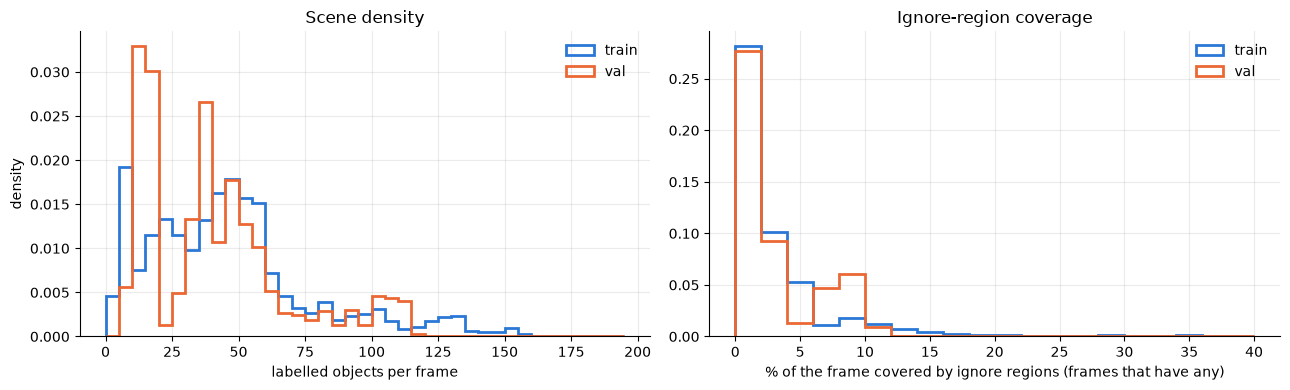

,train,val
mean objects / frame,45.680592,40.1026
median,43.0,37.0
95th percentile,118.0,103.0
max,180,116
frames with no objects,3,0
frames with an ignore region,75%,50%
ignore regions per frame (when present),3.529187,2.785914
median ignore coverage (when present),1.6%,1.4%
95th percentile ignore coverage,11.5%,9.5%
max ignore coverage,38.5%,11.1%


In [ ]:
def per_frame_counts(frames, objs):
    return objs.groupby("image_id").size().reindex(frames.image_id, fill_value=0)

dens = {"train": per_frame_counts(train_frames, train_objs), "val": per_frame_counts(val_frames, val_objs)}

def ignore_coverage(regions):
    """Fraction of each frame covered by ignore regions (sum of areas, capped at 1 since regions can overlap)."""
    area = regions.w * regions.h / (regions.width * regions.height)
    return area.groupby(regions.image_id).sum().clip(upper=1)

cov = {"train": ignore_coverage(train_regions), "val": ignore_coverage(val_regions)}
reg_per_frame = {"train": train_regions.groupby("image_id").size(), "val": val_regions.groupby("image_id").size()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (name, d), col in zip(dens.items(), [BLUE, ORANGE]):
    ax[0].hist(d, bins=np.arange(0, 200, 5), density=True, histtype="step", lw=2, color=col, label=name)
ax[0].set_xlabel("labelled objects per frame")
ax[0].set_ylabel("density")
ax[0].set_title("Scene density")
ax[0].legend(frameon=False)

for (name, c), col in zip(cov.items(), [BLUE, ORANGE]):
    ax[1].hist(c * 100, bins=np.arange(0, 41, 2), density=True, histtype="step", lw=2, color=col, label=name)
ax[1].set_xlabel("% of the frame covered by ignore regions (frames that have any)")
ax[1].set_title("Ignore-region coverage")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame({
    name: {
        "mean objects / frame": d.mean(),
        "median": d.median(),
        "95th percentile": d.quantile(0.95),
        "max": d.max(),
        "frames with no objects": int((d == 0).sum()),
        "frames with an ignore region": f"{len(cov[name]) / len(d):.0%}",
        "ignore regions per frame (when present)": reg_per_frame[name].mean(),
        "median ignore coverage (when present)": f"{cov[name].median():.1%}",
        "95th percentile ignore coverage": f"{cov[name].quantile(0.95):.1%}",
        "max ignore coverage": f"{cov[name].max():.1%}",
    } for name, d in dens.items()
}).round(1)

**Observations**

- Frames are crowded: ~46 labelled objects per frame on average in train (up to 180), and 6-8% of frames have more than 100 objects. The detector must keep many boxes per image, so NMS must not suppress touching neighbours too aggressively and the 500-detections-per-image limit of the scoring is comfortable but not unlimited.
- **Ignore regions are frequent but small:** 75% of train frames (50% of val frames) contain at least one, about 3.5 per such frame, but together they cover only a median ~2% of the frame (95th percentile ~12%, at most ~39%). They mark crowds, packed parking lots and VisDrone's "others" class, i.e. places that **contain real objects that are deliberately unlabelled**.
- If these regions are left alone, a standard detector is trained to treat those unlabelled cars and people as *background*, which teaches it to suppress true positives. The area involved is small, so I expect the effect to be modest, but handling it is cheap.

**Implication:** it is worth handling ignore regions explicitly during preprocessing rather than silently dropping them (details in the next section).

## 5. Occlusion and truncation

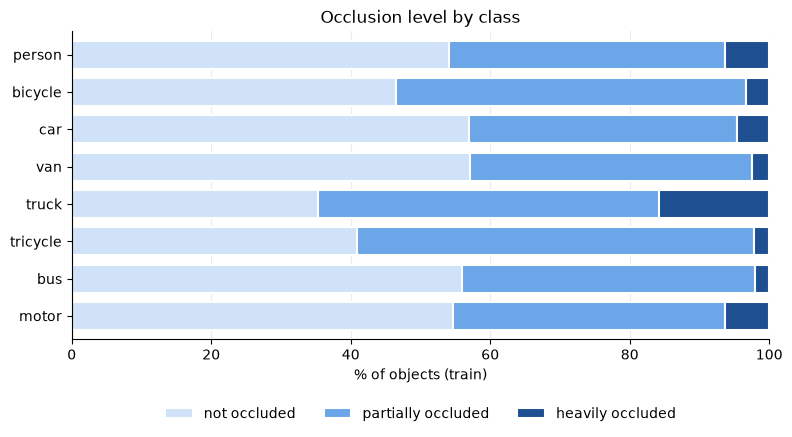

truncated by the image border: train 4.3% | val 5.3%
occluded (partial or heavy):   train 45.7% | val 59.1%


In [ ]:
occ = (pd.crosstab(train_objs.cls_name, train_objs.occlusion, normalize="index").reindex(CLASS_NAMES) * 100)
occ.columns = ["not occluded", "partially occluded", "heavily occluded"]

ax = occ.plot.barh(stacked=True, figsize=(9, 4), color=["#cfe2f7", "#6aa6e8", "#1d4f91"], width=0.75,
                   edgecolor="white", linewidth=1.5)
ax.invert_yaxis()
ax.set_xlabel("% of objects (train)")
ax.set_ylabel("")
ax.set_title("Occlusion level by class")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.show()

print(f"truncated by the image border: train {train_objs.truncation.mean():.1%} | val {val_objs.truncation.mean():.1%}")
print(f"occluded (partial or heavy):   train {(train_objs.occlusion > 0).mean():.1%} | val {(val_objs.occlusion > 0).mean():.1%}")

**Observations**

- Roughly 46% of train objects are at least partially occluded (59% in val). `truck` is the most occluded class (65% occluded, 16% heavily), followed by `tricycle` and `bicycle`.
- Truncation by the image border is rare overall (~4%) but affects the large classes: 14% of `bus` and 11% of `truck` instances are cut off by the frame edge.
- Occlusion is an inherent property of the data, not noise, so I keep occluded objects in training (the test annotations contain them too) and rely on augmentation (mosaic / mixup / copy-paste) to expose the model to more crowding. Random crops should not be too aggressive, or they will keep cutting the large objects further.

## 6. What the data looks like

Densest train frame (left) and a frame from a clip with the most common train resolution, 1904x1071 (right). Coloured boxes are labelled objects; the grey areas are ignore regions.

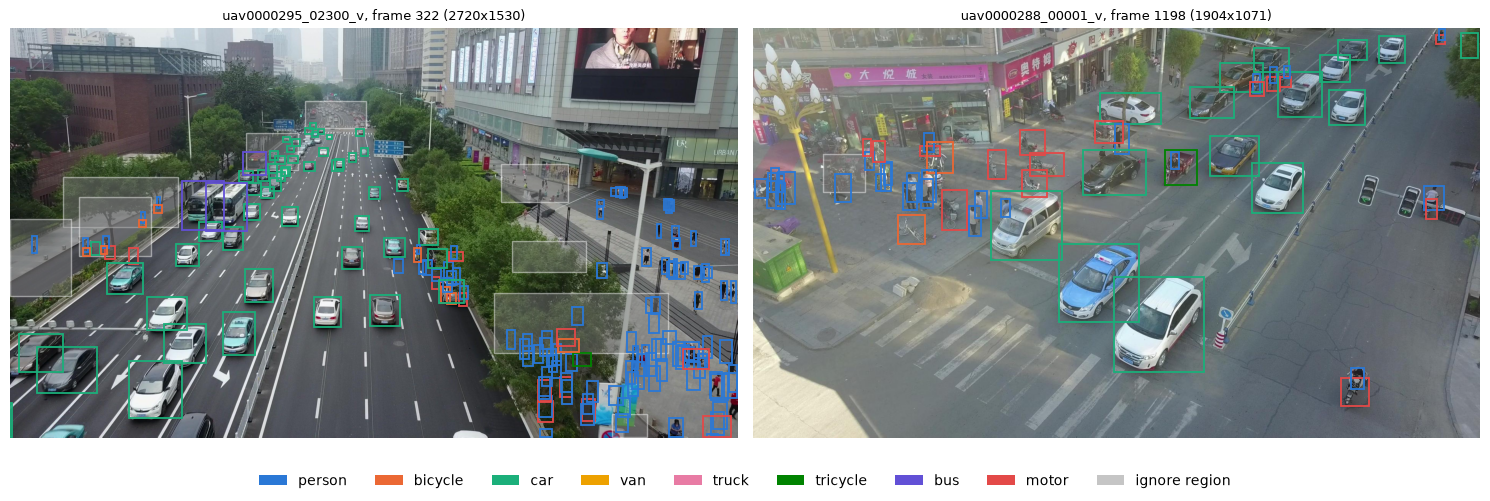

In [ ]:
from matplotlib.patches import Patch, Rectangle


def show_frame(ax, split, frame, objs, regions):
    img = Image.open(DATA / split / frame.file_name)
    ax.imshow(img)
    for r in regions[regions.image_id == frame.image_id].itertuples():
        ax.add_patch(Rectangle((r.x, r.y), r.w, r.h, facecolor="grey", alpha=0.45, edgecolor="white", lw=1))
    for o in objs[objs.image_id == frame.image_id].itertuples():
        ax.add_patch(Rectangle((o.x, o.y), o.w, o.h, fill=False, edgecolor=CLASS_COLORS[o.cls], lw=1.3))
    ax.set_title(f"{frame["clip"]}, frame {frame.frame_id} ({frame.width}x{frame.height})", fontsize=9)
    ax.axis("off")


dense = train_frames[train_frames.image_id == train_objs.groupby("image_id").size().idxmax()].iloc[0]
typical = train_frames[(train_frames.width == train_frames.width.mode()[0]) & (train_frames["clip"] != dense["clip"])]
other = typical.iloc[len(typical) // 2]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
show_frame(axes[0], "train", dense, train_objs, train_regions)
show_frame(axes[1], "train", other, train_objs, train_regions)
fig.legend(handles=[Patch(facecolor=c, label=n) for c, n in zip(CLASS_COLORS, CLASS_NAMES)] +
                   [Patch(facecolor="grey", alpha=0.45, label="ignore region")],
           loc="lower center", ncol=9, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## Summary: what the data tells me

| Finding | Consequence for the experiments |
|---|---|
| Long-tailed classes (`car` 46% vs `bus` <1%); val mix differs from train | Watch per-class AP; consider class weighting / focal loss; keep large and rare objects when augmenting |
| Median object ~2.4% of the long side; about half under 32 px and ~10% under 16 px at 1280 px | Train and infer at high resolution (>= 1280); multi-scale necks / small-object heads |
| Train/val images are bigger than test and test has extra low-res clips | Resize to a fixed network size instead of relying on native pixel sizes; add down-up-scale / blur augmentation |
| ~46 objects per frame, up to 180 | Keep NMS settings permissive, allow many detections per image |
| 75% of train frames have (small) ignore regions with real, unlabelled objects | Mask them during training rather than treating them as background |
| Consecutive frames are near-duplicates (shown below) | Sub-sample frames for training instead of using all 24k |

# Data Preprocessing

## Overview

Preprocessing steps and the reason for each, based on the exploration above:

1. **Integrity checks and cleaning:** make sure the labels are consistent and the boxes valid.
2. **Frame sub-sampling:** consecutive video frames are almost identical, so training on every frame is wasteful.
3. **Ignore-region masking:** stop the detector from learning that unlabelled objects are background.
4. **Input resolution:** choose a network input size that keeps small objects detectable.
5. **Prepared dataset and manifest:** write the masked images, image lists, YOLO config and COCO annotations into a run folder whose `manifest.json` is the hand-off to the model notebooks.

The train/val split that the competition provides is split **by clip**, so it is leakage-free. I keep it as is instead of calling `train_test_split` on frames, which would put near-duplicate frames of the same clip into both sets and inflate validation scores.

### 1. Integrity checks and cleaning

In [ ]:
def check_split(split, frames, objs, regions):
    label_files = sorted((DATA / split / "labels").rglob("*.txt"))
    yolo_lines = sum(len(p.read_text().splitlines()) for p in label_files)
    ignore_lines = sum(len(p.read_text().splitlines()) for p in (DATA / split / "ignore").rglob("*.txt"))
    return {
        "frames": len(frames),
        "YOLO label files": len(label_files),
        "YOLO label lines": yolo_lines,
        "COCO objects": len(objs),
        "ignore label lines": ignore_lines,
        "COCO ignore regions (deduplicated)": len(regions),
        "class ids outside 0-7": int((~objs.cls.between(0, 7)).sum()),
        "boxes with w or h <= 0": int(((objs.w <= 0) | (objs.h <= 0)).sum()),
        "boxes extending outside the image": int(((objs.x < 0) | (objs.y < 0) | (objs.x + objs.w > objs.width) | (objs.y + objs.h > objs.height)).sum()),
        "boxes smaller than 4 px": int(((objs.w < 4) | (objs.h < 4)).sum()),
        "frames without objects": int(len(frames) - objs.image_id.nunique()),
    }

pd.DataFrame({"train": check_split("train", train_frames, train_objs, train_regions),
              "val": check_split("val", val_frames, val_objs, val_regions)})

,train,val
frames,24201,2846
YOLO label files,24201,2846
YOLO label lines,1105516,114132
COCO objects,1105516,114132
ignore label lines,63843,3995
COCO ignore regions (deduplicated),63843,3995
class ids outside 0-7,0,0
boxes with w or h <= 0,0,0
boxes extending outside the image,0,0
boxes smaller than 4 px,0,0


In [ ]:
def clean_objs(objs, min_side=2):
    """Safety net for the annotation table: clip boxes to the image and drop degenerate ones."""
    o = objs.copy()
    x2 = (o.x + o.w).clip(upper=o.width)
    y2 = (o.y + o.h).clip(upper=o.height)
    o["x"], o["y"] = o.x.clip(lower=0), o.y.clip(lower=0)
    o["w"], o["h"] = x2 - o.x, y2 - o.y
    return o[(o.w >= min_side) & (o.h >= min_side)].reset_index(drop=True)

n_before = len(train_objs), len(val_objs)
train_objs, val_objs = clean_objs(train_objs), clean_objs(val_objs)
print(f"removed {n_before[0] - len(train_objs)} train and {n_before[1] - len(val_objs)} val boxes")

removed 0 train and 0 val boxes


The release is clean: YOLO and COCO labels agree one-to-one (and so do the ignore regions, see below), class ids are in range, there are no degenerate or out-of-image boxes (`clean_objs` is a no-op here and only a safety net), and only a handful of train frames have no objects at all, which I keep as legitimate background examples. No boxes need to be removed, so I do not filter by size: even 4-10 px objects are scored and the model should try to find them.

One quirk worth knowing: `annotations_coco.json` lists every ignore region **eight times**, once per class, so that COCO-style evaluation applies it to all categories. The `ignore/*.txt` files confirm the real number of regions, which is what `load_coco` keeps (it deduplicates). The export in step 5 restores the per-category copies for evaluation.

### 2. Frame sub-sampling

Training clips are long (58 to 1,424 frames, median ~380) and recorded at a high frame rate. To see how redundant neighbouring frames are, I track each object (`track_id`) and measure the IoU between its box in frame *t* and frame *t + lag*.

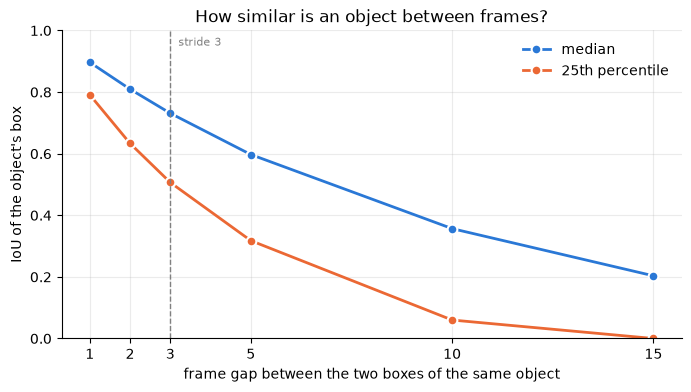

,1,2,3,5,10,15
25th percentile,0.79,0.63,0.51,0.32,0.06,0.0
median,0.90,0.81,0.73,0.60,0.36,0.2


In [ ]:
def iou_at_lag(objs, lag):
    o = objs.sort_values(["clip", "track_id", "frame_id"])
    nxt = o.groupby(["clip", "track_id"])[["x", "y", "w", "h", "frame_id"]].shift(-lag)
    ok = nxt.frame_id == o.frame_id + lag                  # same track, exactly `lag` frames later
    iw = (np.minimum(o.x + o.w, nxt.x + nxt.w) - np.maximum(o.x, nxt.x)).clip(lower=0)
    ih = (np.minimum(o.y + o.h, nxt.y + nxt.h) - np.maximum(o.y, nxt.y)).clip(lower=0)
    inter = iw * ih
    return (inter / (o.w * o.h + nxt.w * nxt.h - inter))[ok]

LAGS = [1, 2, 3, 5, 10, 15]
lag_iou = pd.DataFrame({lag: iou_at_lag(train_objs, lag).quantile([0.25, 0.5]) for lag in LAGS}).T
lag_iou.columns = ["25th percentile", "median"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lag_iou.index, lag_iou["median"], "o-", color=BLUE, lw=2, ms=7, mec="white", mew=1.5, label="median")
ax.plot(lag_iou.index, lag_iou["25th percentile"], "o-", color=ORANGE, lw=2, ms=7, mec="white", mew=1.5, label="25th percentile")
ax.axvline(3, color="grey", ls="--", lw=1)
ax.text(3.2, 0.98, "stride 3", fontsize=8, color="grey", va="top")
ax.set_xlabel("frame gap between the two boxes of the same object")
ax.set_ylabel("IoU of the object's box")
ax.set_ylim(0, 1)
ax.set_xticks(LAGS)
ax.set_title("How similar is an object between frames?")
ax.legend(frameon=False)
plt.show()
lag_iou.round(2).T

In [ ]:
TRAIN_STRIDE = 3


def subsample(frames, stride):
    return frames[(frames.frame_id - 1) % stride == 0].reset_index(drop=True)

train_sel = subsample(train_frames, TRAIN_STRIDE)
print(f"train frames: {len(train_frames):,} -> {len(train_sel):,} (stride {TRAIN_STRIDE}, every clip keeps ~1/{TRAIN_STRIDE} of its frames)")

train frames: 24,201 -> 8,090 (stride 3, every clip keeps ~1/3 of its frames)


Even one frame apart, the median object overlaps its previous self by IoU 0.9, and after 3 frames it is still ~0.73, so the extra frames add very little new information. I sub-sample with **stride 3**: it removes two thirds of the training cost, still leaves ~8k frames in which objects have moved noticeably, and every clip is represented proportionally. Stride 5 (IoU 0.60, ~4.8k frames) would be the next step if training time is short, and a stride of 2 is an option when the budget allows. The stride is a single constant, so it is easy to revisit.

The (small) `val` set is sub-sampled in the same way purely to make validation runs faster. The final numbers come from the leaderboard on the full test set.

### 3. Ignore regions

Ignore regions contain real objects that were intentionally not annotated. The scorer does not penalise detections there, but a detector trained on those frames is told that they are background. Since they appear in 75% of the train frames and masking is cheap, I **grey them out** in the training images, which removes the contradictory supervision. The regions are small, so the gain should be modest and masking is a good candidate for a quick ablation. One catch: a small number of labelled objects overlap an ignore region, which I verify below.

Strategy: fill each ignore region with the neutral grey (114) used by YOLO letterboxing and then **restore the pixels of every labelled box**, so nothing that is labelled is ever erased.

In [ ]:
REGION_COLS, BOX_COLS = ["x", "y", "w", "h"], ["x", "y", "w", "h"]
REGIONS_BY_FRAME = {k: v.to_numpy() for k, v in train_regions.groupby("image_id")[REGION_COLS]}
BOXES_BY_FRAME = {k: v.to_numpy() for k, v in train_objs.groupby("image_id")[BOX_COLS]}


def centres_in_regions(frame_ids):
    inside = total = 0
    for fid in frame_ids:
        regs, boxes = REGIONS_BY_FRAME.get(fid), BOXES_BY_FRAME.get(fid)
        if regs is None or boxes is None:
            total += 0 if boxes is None else len(boxes)
            continue
        cx, cy = (boxes[:, 0] + boxes[:, 2] / 2)[:, None], (boxes[:, 1] + boxes[:, 3] / 2)[:, None]
        hit = (cx >= regs[:, 0]) & (cx <= regs[:, 0] + regs[:, 2]) & (cy >= regs[:, 1]) & (cy <= regs[:, 1] + regs[:, 3])
        inside += int(hit.any(axis=1).sum())
        total += len(boxes)
    return inside, total

inside, total = centres_in_regions(train_sel.image_id)
print(f"labelled objects whose centre lies inside an ignore region: {inside:,} of {total:,} ({inside / total:.1%})")


def mask_ignore_regions(img, regions, keep_boxes, fill=114):
    """Grey out ignore regions of an HxWx3 uint8 image, but keep the pixels of labelled boxes."""
    h, w = img.shape[:2]

    def window(x, y, bw, bh):
        return slice(max(int(y), 0), min(int(np.ceil(y + bh)), h)), slice(max(int(x), 0), min(int(np.ceil(x + bw)), w))

    out = img.copy()
    for r in regions:
        out[window(*r)] = fill
    for b in keep_boxes:
        out[window(*b)] = img[window(*b)]
    return out

labelled objects whose centre lies inside an ignore region: 4,406 of 370,072 (1.2%)


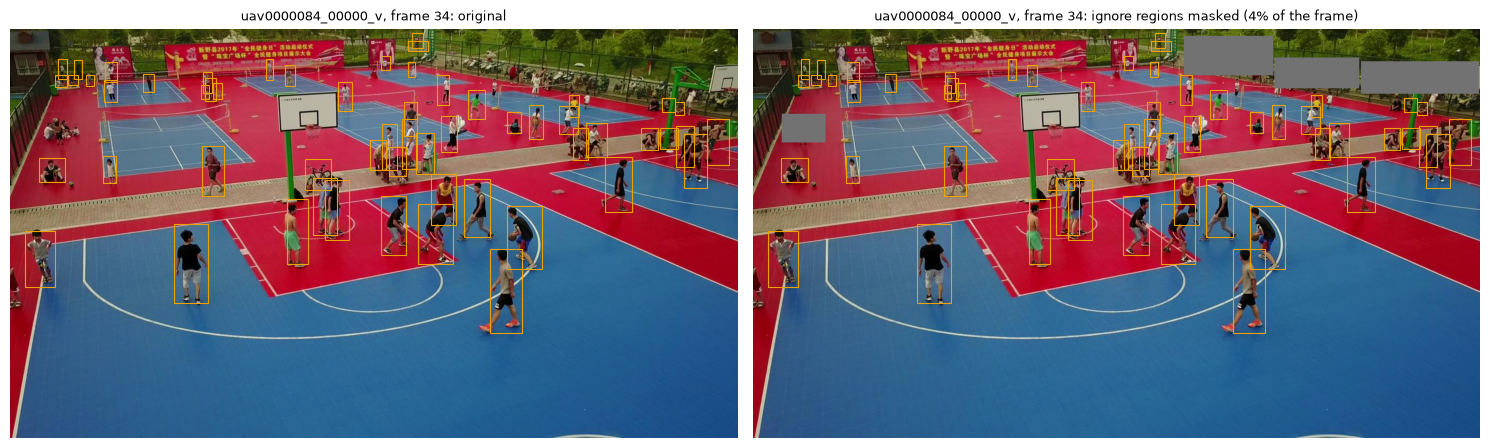

In [ ]:
# Demo on a frame with typical (upper-quartile) ignore coverage
cov_sel = ignore_coverage(train_regions[train_regions.image_id.isin(train_sel.image_id)])
demo_id = (cov_sel - cov_sel.quantile(0.75)).abs().idxmin()
demo = train_sel.set_index("image_id").loc[demo_id]
img = np.asarray(Image.open(DATA / "train" / demo.file_name).convert("RGB"))
masked = mask_ignore_regions(img, REGIONS_BY_FRAME[demo_id], BOXES_BY_FRAME.get(demo_id, ()))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, im, title in zip(axes, [img, masked], ["original", f"ignore regions masked ({cov_sel[demo_id]:.0%} of the frame)"]):
    ax.imshow(im)
    for b in BOXES_BY_FRAME.get(demo_id, ()):
        ax.add_patch(Rectangle((b[0], b[1]), b[2], b[3], fill=False, edgecolor="#eda100", lw=0.8))
    ax.set_title(f"{demo["clip"]}, frame {demo.frame_id}: {title}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Only ~1% of labelled objects (1.2% in the sampled frames) have their centre inside an ignore region, and restoring the labelled boxes keeps those intact, so labels and pixels stay consistent. The `val` images are **not** masked: validation should match what the scorer sees, and a detection in an ignore region is simply not penalised there.

### 4. Input resolution

Because pixel sizes depend on the clip resolution (section 3), the only meaningful lever is the network input size. For each candidate I compute the share of all labelled objects (train + val) that would end up tiny after the resize:

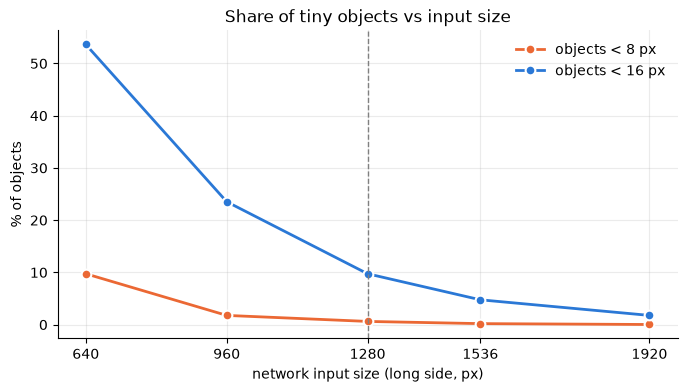

,objects < 8 px,objects < 16 px,objects < 32 px,relative compute (vs 640)
640,9.7%,53.6%,89.2%,1.0x
960,1.8%,23.5%,73.2%,2.2x
1280,0.6%,9.7%,53.6%,4.0x
1536,0.2%,4.8%,39.4%,5.8x
1920,0.0%,1.8%,23.5%,9.0x


In [ ]:
sizes_rel = pd.concat([train_objs.size_rel, val_objs.size_rel])
IMGSZ_GRID = [640, 960, 1280, 1536, 1920]

imgsz_tab = pd.DataFrame({
    sz: {"objects < 8 px": (sizes_rel * sz < 8).mean(),
         "objects < 16 px": (sizes_rel * sz < 16).mean(),
         "objects < 32 px": (sizes_rel * sz < 32).mean(),
         "relative compute (vs 640)": (sz / 640) ** 2}
    for sz in IMGSZ_GRID
}).T

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in [("objects < 8 px", ORANGE), ("objects < 16 px", BLUE)]:
    ax.plot(imgsz_tab.index, imgsz_tab[col] * 100, "o-", color=color, lw=2, ms=7, mec="white", mew=1.5, label=col)
ax.axvline(1280, color="grey", ls="--", lw=1)
ax.set_xticks(IMGSZ_GRID)
ax.set_xlabel("network input size (long side, px)")
ax.set_ylabel("% of objects")
ax.set_title("Share of tiny objects vs input size")
ax.legend(frameon=False)
plt.show()

imgsz_tab.assign(**{c: imgsz_tab[c].map("{:.1%}".format) for c in imgsz_tab.columns[:3]},
                 **{"relative compute (vs 640)": imgsz_tab["relative compute (vs 640)"].map("{:.1f}x".format)})

At 640 px (the usual default) about half of all objects are below 16 px and ~10% below 8 px, which is hard even for the finest (stride-8) detection head. At **1280 px** that drops to ~10% under 16 px and under 1% under 8 px, while the compute is 4x that of 640. Going to 1920 px would cost another 2.25x for little extra gain on the 680-1360 px test clips (they would just be upsampled). I therefore fix **`IMGSZ = 1280`** for training, and for inference I can try a larger size as test-time augmentation. Images are letterboxed (aspect ratio preserved, padded with grey 114), never stretched.

### 5. Prepared dataset and manifest

This notebook hands the data to the model notebooks through a **run folder**. Everything lives in one place, `hw2_data.DATA_ROOT/<run_id>/`, outside the repo (default `~/.cache/hw2_prepared`, override with the `HW2_DATA_ROOT` environment variable). The `run_id` is built from the settings chosen above, so changing the stride or the image size creates a new folder instead of silently mixing old and new files.

```
<run_id>/
  train/images/<clip>/<frame>.jpg   sub-sampled frames: masked copy, or symlink to the original when there is nothing to mask
  train/labels                      -> original YOLO labels
  val/images, val/labels            -> original val data (not masked)
  test, test_images.csv             -> original test images and their list
  train.txt, val.txt                image lists (paths relative to the run folder)
  coco/train.json, coco/val.json    COCO annotations of exactly these frames
  data.yaml                         Ultralytics config
  manifest.json                     written LAST: the definition of the run
```

`manifest.json` records the settings, label conventions, file locations and counts. It is created only after everything else was written (and deleted when a run is rebuilt), so **a run without a manifest is incomplete**. The model notebooks never touch the Kaggle download; they call `hw2_data.load_run()`, which reads the manifest of the latest run, and fail with a clear message when there is none.

COCO category ids are 1-based (YOLO id + 1) and ignore regions are `iscrowd = 1` boxes repeated once per category, exactly like the source annotations, so `pycocotools` evaluation on `val.json` treats them as "don't care" for every class.

In [ ]:
import shutil
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone

import hw2_data

IMGSZ = 1280
VAL_STRIDE = 3
FILL = 114  # grey of the masked regions (same as the YOLO letterbox padding)

RUN_ID = f"train-s{TRAIN_STRIDE}_val-s{VAL_STRIDE}_sz{IMGSZ}"
RUN = hw2_data.DATA_ROOT / RUN_ID
RUN.mkdir(parents=True, exist_ok=True)
(RUN / "manifest.json").unlink(missing_ok=True)   # a run is only complete once the manifest is written again at the end

val_sel = subsample(val_frames, VAL_STRIDE)


def link(dst, src):
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.is_symlink():
        dst.unlink()
    dst.symlink_to(src)


def write_train_frame(row):
    dst = RUN / "train" / row.file_name                    # file_name = images/<clip>/<frame>.jpg
    if dst.exists() or dst.is_symlink():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    src = DATA / "train" / row.file_name
    regions = REGIONS_BY_FRAME.get(row.image_id)
    if regions is None:
        dst.symlink_to(src)
        return
    img = np.asarray(Image.open(src).convert("RGB"))
    masked = mask_ignore_regions(img, regions, BOXES_BY_FRAME.get(row.image_id, ()), fill=FILL)
    Image.fromarray(masked).save(dst, quality=95)


# 1. images and links to the untouched parts of the download
link(RUN / "train" / "labels", DATA / "train" / "labels")
link(RUN / "val" / "images", DATA / "val" / "images")
link(RUN / "val" / "labels", DATA / "val" / "labels")
link(RUN / "test", DATA / "test")
shutil.copy(DATA / "test_images.csv", RUN / "test_images.csv")

with ThreadPoolExecutor(8) as pool:
    list(pool.map(write_train_frame, train_sel.itertuples()))

# 2. image lists (relative paths: Ultralytics resolves "./" against the folder of the list) and YOLO config
def image_list(split, frames):
    return "\n".join(f"./{split}/{f}" for f in frames.file_name) + "\n"

(RUN / "train.txt").write_text(image_list("train", train_sel))
(RUN / "val.txt").write_text(image_list("val", val_sel))
(RUN / "data.yaml").write_text(
    f"path: {RUN}\ntrain: train.txt\nval: val.txt\nnc: 8\nnames: {CLASS_NAMES}\n".replace("'", '"')
)


# 3. COCO annotations of the selected frames
def export_coco(frames, objs, regions, split):
    ids = set(frames.image_id)
    images = [{"id": i, "file_name": f"{split}/{f}", "width": w, "height": h, "clip": c, "frame_id": n}
              for i, f, w, h, c, n in zip(frames.image_id, frames.file_name, frames.width, frames.height,
                                          frames["clip"], frames.frame_id)]
    annotations = [{"id": o.id, "image_id": o.image_id, "category_id": o.cls + 1, "bbox": [o.x, o.y, o.w, o.h],
                    "area": o.w * o.h, "iscrowd": 0, "occlusion": int(o.occlusion), "truncation": int(o.truncation),
                    "track_id": o.track_id}
                   for o in objs[objs.image_id.isin(ids)].itertuples()]
    next_id = int(objs.id.max()) + 1                       # region ids are regenerated, above every object id
    for r in regions[regions.image_id.isin(ids)].itertuples():
        for category_id in range(1, len(CLASS_NAMES) + 1):  # source convention: one iscrowd copy per category
            annotations.append({"id": next_id, "image_id": r.image_id, "category_id": category_id,
                                "bbox": [r.x, r.y, r.w, r.h], "area": r.w * r.h, "iscrowd": 1})
            next_id += 1
    return {"info": {"description": f"hw2 prepared run {RUN_ID}, split {split}"},
            "categories": [{"id": i + 1, "name": n} for i, n in enumerate(CLASS_NAMES)],
            "images": images, "annotations": annotations}


(RUN / "coco").mkdir(exist_ok=True)
coco = {"train": export_coco(train_sel, train_objs, train_regions, "train"),
        "val": export_coco(val_sel, val_objs, val_regions, "val")}
for split, d in coco.items():
    (RUN / "coco" / f"{split}.json").write_text(json.dumps(d))

# 4. the manifest, written last
n_obj = {s: sum(a["iscrowd"] == 0 for a in d["annotations"]) for s, d in coco.items()}
manifest = {
    "run_id": RUN_ID,
    "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "config": {"train_stride": TRAIN_STRIDE, "val_stride": VAL_STRIDE, "imgsz": IMGSZ, "ignore_fill": FILL,
               "mask_train_ignore_regions": True, "min_box_side": 2, "class_names": CLASS_NAMES},
    "conventions": {
        "yolo_class_ids": "0-7 in class_names order",
        "coco_category_ids": "1-8 (yolo id + 1)",
        "coco_file_names": "relative to the run folder",
        "coco_ignore_regions": "iscrowd=1, one copy per category (as in the source annotations)",
        "val_images_masked": False,
    },
    "files": {"data_yaml": "data.yaml", "train_list": "train.txt", "val_list": "val.txt",
              "train_coco": "coco/train.json", "val_coco": "coco/val.json",
              "test_images_csv": "test_images.csv", "test_images_dir": "test/images"},
    "stats": {"train_frames": len(train_sel), "val_frames": len(val_sel), "test_frames": len(test_frames),
              "train_objects": n_obj["train"], "val_objects": n_obj["val"],
              "train_masked_frames": sum(i in REGIONS_BY_FRAME for i in train_sel.image_id)},
    "source": {"competition": "multiple-object-video-detection-hw-2-ucu-ai-2026", "raw_root": str(DATA)},
}
(RUN / "manifest.json").write_text(json.dumps(manifest, indent=2))
(hw2_data.DATA_ROOT / "latest.txt").write_text(RUN_ID)

print(f"run written to {RUN}")
print(json.dumps(manifest["stats"], indent=2))

run written to /Users/ruzhylopv/.cache/hw2_prepared/train-s3_val-s3_sz1280
{
  "train_frames": 8090,
  "val_frames": 951,
  "test_frames": 3811,
  "train_objects": 370072,
  "val_objects": 38206,
  "train_masked_frames": 6053
}


Last, a consumer check: it loads the run **the way the model notebooks will** (only through `hw2_data.load_run`, no variable from this notebook) and verifies that every file the manifest promises is there and that the YOLO lists, COCO files and counts agree.

In [ ]:
m = hw2_data.load_run()
assert m["run_id"] == RUN_ID

rows = {}
for split in ("train", "val"):
    listed = m["paths"][f"{split}_list"].read_text().split()
    coco_split = json.load(open(m["paths"][f"{split}_coco"]))
    missing_img = [l for l in listed if not (m["root"] / l).exists()]
    missing_lbl = [l for l in listed if not Path(str(m["root"] / l).replace("/images/", "/labels/")).with_suffix(".txt").exists()]
    n_obj = sum(a["iscrowd"] == 0 for a in coco_split["annotations"])
    n_reg = sum(a["iscrowd"] == 1 for a in coco_split["annotations"]) // len(CLASS_NAMES)

    first = coco_split["images"][0]
    assert Image.open(m["root"] / first["file_name"]).size == (first["width"], first["height"])
    assert not missing_img and not missing_lbl
    assert len(listed) == len(coco_split["images"]) == m["stats"][f"{split}_frames"]
    assert n_obj == m["stats"][f"{split}_objects"]
    rows[split] = {"frames in list": len(listed), "frames in COCO": len(coco_split["images"]), "objects": n_obj,
                   "ignore regions": n_reg, "missing images": len(missing_img), "missing labels": len(missing_lbl)}

test_csv = pd.read_csv(m["paths"]["test_images_csv"])
assert len(test_csv) == m["stats"]["test_frames"]
assert all((m["root"] / f).exists() for f in test_csv.file_name)
print(f"manifest OK: run {m['run_id']} created {m['created']}; {len(test_csv):,} test images reachable")
pd.DataFrame(rows)

manifest OK: run train-s3_val-s3_sz1280 created 2026-10-25T16:35:00+00:00; 3,811 test images reachable


,train,val
frames in list,8090,951
frames in COCO,8090,951
objects,370072,38206
ignore regions,21394,1338
missing images,0,0
missing labels,0,0


## Summary of the preprocessing pipeline

| Step | Choice | Why |
|---|---|---|
| Split | Provided clip-level train/val | No frame leakage between train and val |
| Cleaning | Clip boxes to the image, drop boxes < 2 px (nothing to remove here) | Safety net; keep tiny objects since they are scored |
| Frame sampling | Every 3rd frame (24,201 -> 8,090 train frames) | Neighbouring frames are near-duplicates (median IoU 0.73 after 3 frames) |
| Ignore regions | Grey out in train images, keep labelled boxes | Unlabelled objects must not be learned as background |
| Resolution | Letterbox to 1280 px long side, aspect ratio preserved | ~10% of objects are < 16 px at 1280 vs ~50% at 640; handles the differently sized train/test frames |
| Hand-off | One run folder per configuration, `manifest.json` written last, loaded with `hw2_data.load_run()` | The model notebooks depend on a verified run, not on this notebook's variables |
| Class imbalance, occlusion, scale gap | Not preprocessed; handled in the training sections via loss weighting and augmentation (mosaic, scale jitter, down-up-scale blur) | Tied to the model's training loop |

# Two-stage Anchor-based

# One-stage Anchor-based


# One-stage Anchor-free

# Query-based


# Custom Pipeline

# Visualizaiton (Bonus)

# Submission

In [ ]:
# ============================================================
# Work in progress, needs cleaning
# ============================================================
import os
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------- Config ----------------
SAMPLE_SUB_PATH = "/kaggle/input/<competition>/sample_submission.csv"  # <-- edit
TEST_IMG_DIR    = "/kaggle/input/<competition>/test/images"            # <-- edit
OUTPUT_PATH     = "submission.csv"

MAX_DETS        = 500      # only the first 500 per image are scored
MIN_SCORE       = 0.001    # drop very low-confidence boxes (keep low for mAP)
ROUND_COORDS    = False    # True -> integer pixel coords like the sample
COORD_DECIMALS  = 2
SCORE_DECIMALS  = 4


# ---------------- Core helpers ----------------
def format_prediction_string(classes, scores, boxes_xywh):
    """
    classes:    (N,) int class ids
    scores:     (N,) float confidences
    boxes_xywh: (N, 4) [x_topleft, y_topleft, width, height] in pixels
    Returns the space-separated PredictionString ('' when there are no detections).
    """
    classes = np.asarray(classes).reshape(-1)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    boxes = np.asarray(boxes_xywh, dtype=float).reshape(-1, 4)

    if len(scores) == 0:
        return ""

    # Filter invalid / low-score boxes
    keep = (scores >= MIN_SCORE) & (boxes[:, 2] > 0) & (boxes[:, 3] > 0)
    classes, scores, boxes = classes[keep], scores[keep], boxes[keep]

    # Keep the top MAX_DETS by score
    order = np.argsort(-scores)[:MAX_DETS]
    classes, scores, boxes = classes[order], scores[order], boxes[order]

    parts = []
    for c, s, (x, y, w, h) in zip(classes, scores, boxes):
        if ROUND_COORDS:
            coords = f"{int(round(x))} {int(round(y))} {int(round(w))} {int(round(h))}"
        else:
            d = COORD_DECIMALS
            coords = f"{x:.{d}f} {y:.{d}f} {w:.{d}f} {h:.{d}f}"
        parts.append(f"{int(c)} {s:.{SCORE_DECIMALS}f} {coords}")
    return " ".join(parts)


def xyxy_to_xywh(boxes_xyxy, img_w=None, img_h=None):
    """Convert [x1, y1, x2, y2] -> [x, y, w, h] (top-left), optionally clipping to the image."""
    b = np.asarray(boxes_xyxy, dtype=float).reshape(-1, 4).copy()
    if img_w is not None and img_h is not None:
        b[:, [0, 2]] = b[:, [0, 2]].clip(0, img_w)
        b[:, [1, 3]] = b[:, [1, 3]].clip(0, img_h)
    return np.stack([b[:, 0], b[:, 1], b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]], axis=1)


def build_submission(predictions, sample_sub_path=SAMPLE_SUB_PATH, output_path=OUTPUT_PATH):
    """
    predictions: dict {image_id: (classes, scores, boxes_xywh)}
    Uses sample_submission.csv for the image list and order; images with no
    prediction get an empty PredictionString.
    """
    sample = pd.read_csv(sample_sub_path)
    sample_ids = sample["image_id"].astype(str).tolist()

    rows = []
    for img_id in sample_ids:
        if img_id in predictions:
            c, s, b = predictions[img_id]
            rows.append(format_prediction_string(c, s, b))
        else:
            rows.append("")

    sub = pd.DataFrame({"image_id": sample_ids, "PredictionString": rows})

    # Sanity checks
    extra = set(predictions) - set(sample_ids)
    if extra:
        print(f"[warn] {len(extra)} predicted image_ids are not in sample_submission "
              f"(e.g. {list(extra)[:3]}); they were ignored.")
    assert len(sub) == len(sample), "Row count mismatch with sample_submission"
    assert sub["image_id"].is_unique, "Duplicate image_ids in submission"

    # Empty strings must be written as empty, not NaN
    sub["PredictionString"] = sub["PredictionString"].fillna("")
    sub.to_csv(output_path, index=False)

    n_empty = (sub["PredictionString"] == "").sum()
    n_dets = sub["PredictionString"].str.split().str.len().fillna(0).sum() // 6
    print(f"Saved {output_path}: {len(sub)} rows | {n_empty} empty | {int(n_dets)} total detections")
    return sub


# ---------------- Optional: Ultralytics YOLO inference -> predictions ----------------
def predict_with_ultralytics(model, img_dir=TEST_IMG_DIR, imgsz=640, conf=MIN_SCORE,
                             iou=0.6, batch=16, augment=False, device=None):
    """Run a YOLO model over img_dir and return a predictions dict for build_submission."""
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    paths = sorted(str(p) for p in Path(img_dir).iterdir() if p.suffix.lower() in exts)

    predictions = {}
    for i in range(0, len(paths), batch):
        results = model.predict(
            paths[i:i + batch], imgsz=imgsz, conf=conf, iou=iou,
            max_det=MAX_DETS, augment=augment, device=device, verbose=False,
        )
        for r in results:
            img_id = Path(r.path).stem
            h, w = r.orig_shape
            if r.boxes is None or len(r.boxes) == 0:
                predictions[img_id] = ([], [], np.zeros((0, 4)))
                continue
            xyxy = r.boxes.xyxy.cpu().numpy()          # already in original-image pixels
            predictions[img_id] = (
                r.boxes.cls.cpu().numpy().astype(int),
                r.boxes.conf.cpu().numpy(),
                xyxy_to_xywh(xyxy, w, h),
            )
        print(f"\rInference: {min(i + batch, len(paths))}/{len(paths)}", end="")
    print()
    return predictions


# ---------------- Run ----------------
# from ultralytics import YOLO
# model = YOLO("/kaggle/working/runs/detect/train/weights/best.pt")
# predictions = predict_with_ultralytics(model, imgsz=1280)
#
# Or supply your own dict:
# predictions = {"clip_001_0000001": ([2, 0], [0.91, 0.55], [[1366, 580, 26, 44], [809, 625, 29, 66]])}

submission = build_submission(predictions)
submission.head(10)

In [ ]:
!kaggle competitions submit -c multiple-object-video-detection-hw-2-ucu-ai-2026 -f submission.csv -m "Proba 1"